# Experiment 5: Morphological Analysis and Part-of-Speech (POS) Tagging System

### Problem Statement:
Implement a Morphological Analysis and Part-of-Speech (POS) Tagging system to identify grammatical structures and linguistic properties of words within sentences.


In [1]:
import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Ensure Treebank corpus and taggers are available
for pkg in ['treebank', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng', 'punkt', 'punkt_tab']:
    nltk.download(pkg, quiet=True)

nlp = spacy.load("en_core_web_sm")
print("POS Tagging modules and Treebank corpora loaded successfully.")


POS Tagging modules and Treebank corpora loaded successfully.


In [2]:
morph_sentence = "The experienced engineers were optimizing advanced neural networks for mobile deployment."
doc_morph = nlp(morph_sentence)

morph_records = []
for token in doc_morph:
    morph_dict = token.morph.to_dict()
    morph_records.append({
        "Token": token.text,
        "Lemma": token.lemma_,
        "POS": token.pos_,
        "Morphological Features": str(morph_dict) if morph_dict else "None",
        "Number": morph_dict.get("Number", "-"),
        "Tense": morph_dict.get("Tense", "-"),
        "VerbForm": morph_dict.get("VerbForm", "-"),
        "Degree": morph_dict.get("Degree", "-")
    })

df_morph = pd.DataFrame(morph_records)
print("--- Detailed Morphological Feature Breakdown ---")
print(df_morph.to_string(index=False))


--- Detailed Morphological Feature Breakdown ---
      Token       Lemma   POS                                  Morphological Features Number Tense VerbForm Degree
        The         the   DET                  {'Definite': 'Def', 'PronType': 'Art'}      -     -        -      -
experienced experienced   ADJ                                       {'Degree': 'Pos'}      -     -        -    Pos
  engineers    engineer  NOUN                                      {'Number': 'Plur'}   Plur     -        -      -
       were          be   AUX     {'Mood': 'Ind', 'Tense': 'Past', 'VerbForm': 'Fin'}      -  Past      Fin      -
 optimizing    optimize  VERB {'Aspect': 'Prog', 'Tense': 'Pres', 'VerbForm': 'Part'}      -  Pres     Part      -
   advanced    advanced   ADJ                                       {'Degree': 'Pos'}      -     -        -    Pos
     neural      neural   ADJ                                       {'Degree': 'Pos'}      -     -        -    Pos
   networks     network  NOUN  

In [3]:
from nltk.corpus import treebank
from nltk.tag import DefaultTagger, RegexpTagger, UnigramTagger, BigramTagger

# Load Penn Treebank tagged sentences
tagged_sents = treebank.tagged_sents()
train_size = int(len(tagged_sents) * 0.8)
train_sents = tagged_sents[:train_size]
test_sents = tagged_sents[train_size:]

print(f"Penn Treebank Dataset: {len(tagged_sents)} sentences ({train_size} train, {len(test_sents)} test)")

# 1. Default Tagger (Most frequent tag in English is NN)
t0 = DefaultTagger('NN')

# 2. Regular Expression Tagger (Morphological heuristics)
patterns = [
    (r'.*ing$', 'VBG'),               # Gerunds
    (r'.*ed$', 'VBD'),                # Simple past
    (r'.*es$', 'VBZ'),                # 3rd singular present
    (r'.*ould$', 'MD'),               # Modals
    (r".*'s$", "NN$"),               # Possessive nouns
    (r'.*s$', 'NNS'),                 # Plural nouns
    (r'^-?[0-9]+(\.[0-9]+)?$', 'CD'), # Cardinal numbers
    (r'.*ly$', 'RB'),                 # Adverbs
    (r'.*able$', 'JJ'),               # Adjectives
    (r'.*tion$', 'NN'),               # Abstract nouns
    (r'.*', 'NN')                     # Default fallback
]
t1 = RegexpTagger(patterns, backoff=t0)

# 3. Unigram Tagger with Regex Backoff
t2 = UnigramTagger(train_sents, backoff=t1)

# 4. Bigram Tagger with Sequential Backoff Chain
t3 = BigramTagger(train_sents, backoff=t2)

# Evaluation on Test Sentences
acc_default = t0.accuracy(test_sents)
acc_regex = t1.accuracy(test_sents)
acc_unigram = t2.accuracy(test_sents)
acc_bigram = t3.accuracy(test_sents)

df_tagger_acc = pd.DataFrame({
    "Tagger Architecture": ["1. Default Tagger (NN)", "2. Regexp Affix Tagger", "3. Unigram Tagger (w/ Backoff)", "4. Bigram Tagger (w/ Backoff Chain)"],
    "Test Accuracy": [f"{acc_default*100:.2f}%", f"{acc_regex*100:.2f}%", f"{acc_unigram*100:.2f}%", f"{acc_bigram*100:.2f}%"]
})

print("\n--- NLTK Tagger Accuracy Benchmarks on Penn Treebank ---")
print(df_tagger_acc.to_string(index=False))


Penn Treebank Dataset: 3914 sentences (3131 train, 783 test)



--- NLTK Tagger Accuracy Benchmarks on Penn Treebank ---
                Tagger Architecture Test Accuracy
             1. Default Tagger (NN)        14.48%
             2. Regexp Affix Tagger        24.99%
     3. Unigram Tagger (w/ Backoff)        89.99%
4. Bigram Tagger (w/ Backoff Chain)        90.70%


In [4]:
ambiguous_sentences = [
    "The bank can bank on bank deposits.",
    "Time flies like an arrow.",
    "Fruit flies like a banana."
]

print("--- Syntactic Ambiguity Resolution via SpaCy & Averaged Perceptron ---")
for sent in ambiguous_sentences:
    print(f"\nSentence: '{sent}'")
    
    # SpaCy Tagging
    doc = nlp(sent)
    spacy_tags = [(t.text, t.pos_, t.tag_, t.dep_) for t in doc]
    
    df_ambig = pd.DataFrame(spacy_tags, columns=["Token", "Universal POS", "Treebank Tag", "Dependency Relation"])
    print(df_ambig.to_string(index=False))


--- Syntactic Ambiguity Resolution via SpaCy & Averaged Perceptron ---

Sentence: 'The bank can bank on bank deposits.'
   Token Universal POS Treebank Tag Dependency Relation
     The           DET           DT                 det
    bank          NOUN           NN               nsubj
     can           AUX           MD                 aux
    bank          VERB           VB                ROOT
      on           ADP           IN                prep
    bank          NOUN           NN            compound
deposits          NOUN          NNS                pobj
       .         PUNCT            .               punct

Sentence: 'Time flies like an arrow.'
Token Universal POS Treebank Tag Dependency Relation
 Time          NOUN           NN               nsubj
flies          VERB          VBZ                ROOT
 like           ADP           IN                prep
   an           DET           DT                 det
arrow          NOUN           NN                pobj
    .         PUNCT

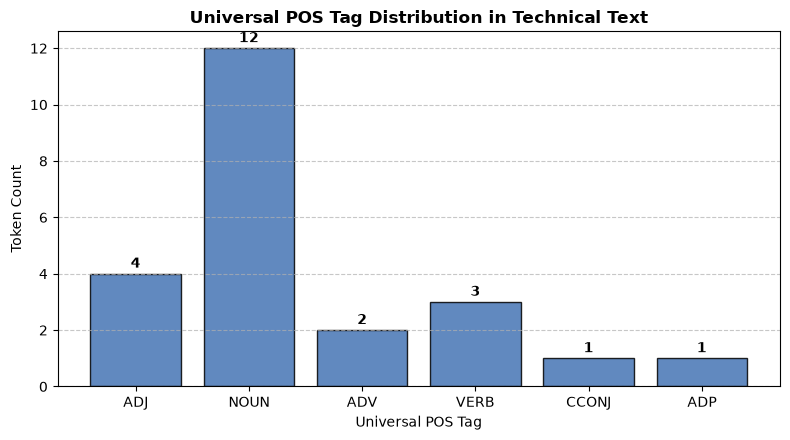

In [5]:
sample_text = (
    "Artificial intelligence algorithms rapidly analyze complex datasets. "
    "Neural network models discover latent representations and patterns automatically. "
    "Engineers build scalable architectures for production environments."
)

doc_dist = nlp(sample_text)
pos_counts = Counter([token.pos_ for token in doc_dist if not token.is_punct])

plt.figure(figsize=(8, 4.5))
bars = plt.bar(pos_counts.keys(), pos_counts.values(), color='#4575b4', edgecolor='black', alpha=0.85)
plt.title("Universal POS Tag Distribution in Technical Text", fontsize=12, fontweight='bold')
plt.xlabel("Universal POS Tag", fontsize=10)
plt.ylabel("Token Count", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.1, int(y), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()
